# 04 — Classification (block C)

**Question of this block.** How well do weather, location and population predict our historical PM10 exceedance indicator in the 284 cities? Which weather does a model need, and for which type of city does it work? The models predict an indicator; they do not split the pollution into a "weather share" and a "city share".

This is **supervised** learning: the target is known for every city, and the models must predict it for cities they have not seen. The pollution variables are never used as predictors (they are the outcome, not the cause), and neither are the groups or the clusters (they are built from position or from pollution). Two models are used, because each answers a different question: a **random forest** to predict and to find which weather it needs, and a **logistic regression**, a simpler model that serves as a comparison. Before any model is read, it has to earn it: it must beat the baseline, also when whole geographic blocks of cities are left out.

1. The target and the baseline
2. The predictors, in three nested sets
3. How the models are validated (random and geographic cross-validation)
4. What block B leads us to expect
5. Which model, with which predictors
6. Random forest: which weather it needs (permutation importance)
7. Which cities the model gets wrong, and how strict the geographic test is
8. Final link: the predictions by cluster of block B
9. Output and summary

**Input:** `data/processed/cities.csv` (notebook 01) with the shared groups and logarithms of `src/groups.py`; `data/processed/clusters.csv` (notebook 03), only in section 8, never as a predictor.

**Output:** `data/processed/classification.csv` (one row per city, with its model scores), `classification_models.csv` and `classification_checks.csv` (the numbers of this notebook, read by `src/make_numbers.py`), figures C1–C5 in `figures/`.


In [1]:
# Libraries, shared project modules (style, maps, groups, validation) and the data with the clusters of notebook 03
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score, confusion_matrix
from sklearn.inspection import permutation_importance

# Shared style, maps, groups and validation: the same for the whole project, in src/
sys.path.append("../src")
from style import (apply_style, source, show, GROUP_ORDER, GROUP_COLOURS, CLUSTER_COLOURS, BLUE, GREY, INK, INK_2,
                   MUTED, DOT_EDGE, GRID)
from maps import draw_europe, to_map
from groups import add_groups, add_logs
from validation import spatial_blocks, SEED, out_of_fold as shared_out_of_fold
apply_style()

cities = pd.read_csv("../data/processed/cities.csv")
cities = add_logs(add_groups(cities))          # adds group, po_valley, region and the log_ columns
clusters = pd.read_csv("../data/processed/clusters.csv")
cities = cities.merge(clusters[["country", "city", "cluster_k2", "cluster_k4", "cluster_k2_name", "cluster_k4_name"]],
                      on=["country", "city"],
                      how="left", validate="one_to_one")
assert cities["cluster_k2"].notna().all()      # every city has its cluster from notebook 03
milan = cities[cities["city"] == "Milano (greater city)"].iloc[0]
print(cities.shape)

(284, 40)


## 1. The target and the baseline

`exceeds_pm10_limit` is True when a city has, on average over 2016–2023, more than 35 days a year with PM10 above 50 µg/m³ (the EU daily limit). It is *our* indicator, a mean over background stations and years, not the legal assessment, which is done station by station and year by year. It counts the days **observed** above 50: a station-year enters with at least 274 valid days, and the missing days are not filled in (the median coverage is 98%, but 331 of the 4,213 PM10 station-years are below 90%). **"Over the limit" in this notebook** always means over this PM10 exceedance indicator, as in notebooks 02 and 03.

In [2]:
# The target as 0/1, and how the 30 cities over the limit are spread over the groups
y = cities["exceeds_pm10_limit"].astype(int)
print("Cities over the limit:", y.sum(), "of", len(y), f"({y.mean():.1%})")
display(show(pd.crosstab(cities["group"], cities["exceeds_pm10_limit"]).reindex(GROUP_ORDER)
     .rename(columns={False: "under the limit", True: "over the limit"}), 0))

# The baseline: a "model" that always answers "no"
always_no = np.zeros(len(y))
print(f"Always 'no': accuracy {np.mean(always_no == y):.3f}, "
      f"balanced accuracy {balanced_accuracy_score(y, always_no):.3f}, AUC 0.5 (no ranking at all)")

Cities over the limit: 30 of 284 (10.6%)


exceeds_pm10_limit,under the limit,over the limit
group,,
Po Valley,8,17
Poland,24,8
Rest of Europe,222,5


Always 'no': accuracy 0.894, balanced accuracy 0.500, AUC 0.5 (no ranking at all)


In [3]:
# How much does the target depend on missing days? A sensitivity check, not a correction.
# Each station-year count is scaled by (days in the year / valid days), then averaged as for the target.
# This assumes that the missing days are like the measured ones, which is not known.
pm = pd.read_csv("../data/interim/coverage_pm_station_years.csv")
pm = pm[(pm["pollutant"] == "PM10") & pm["year"].between(2016, 2023) & (pm["valid_days"] >= 274)]
pm = pm.merge(cities[["country", "city"]], on=["country", "city"], validate="many_to_one")
days_in_year = np.where(pm["year"] % 4 == 0, 366, 365)
pm["coverage"] = pm["valid_days"] / days_in_year
pm["annualised"] = pm["days_above_50"] * days_in_year / pm["valid_days"]

def city_mean(column):
    """Mean of the stations in each year, then mean over the years: the same steps as the target."""
    return pm.groupby(["country", "city", "year"])[column].mean().groupby(["country", "city"]).mean()

observed, annualised = city_mean("days_above_50"), city_mean("annualised")
key = pd.MultiIndex.from_frame(cities[["country", "city"]])
assert ((observed.reindex(key) > 35).to_numpy() == cities["exceeds_pm10_limit"].to_numpy()).all()   # same target
print(f"PM10 station-years: {len(pm)}; coverage below 90%: {(pm['coverage'] < 0.9).sum()}; "
      f"median coverage {pm['coverage'].median():.1%}")
print(f"Cities over 35 days: observed {(observed > 35).sum()}, annualised {(annualised > 35).sum()}")
changed = (observed <= 35) & (annualised > 35)
show(pd.DataFrame({"observed days > 50": observed, "annualised": annualised})
     [changed | (observed.index.get_level_values("city") == milan["city"])].droplevel("country"), 2)


PM10 station-years: 4213; coverage below 90%: 331; median coverage 98.1%
Cities over 35 days: observed 30, annualised 32


,observed days > 50,annualised
city,,
Milano (greater city),50.32,53.35
Piacenza,34.50,35.34
Kielce,34.26,35.46


Two cities sit just under the line and would cross it if their missing days were like the measured ones: **Piacenza** (34.5 → 35.3) and **Kielce** (34.3 → 35.5). Milan stays far above (50.3 → 53.4). We keep the observed count, because it is what was measured, and read the target as "observed exceedance days": the two borderline labels depend on data availability, a limit of the target (see the summary).


Only 30 cities out of 284 exceed the limit. With such an imbalance, **accuracy is useless**: a model that always answers "no" is right 89.4% of the times and has learned nothing. So every result below is given as:

- **AUC**: the probability that a random city over the limit gets a higher score than a random city under it. 0.5 = no better than chance, 1 = perfect ranking. It does not depend on a threshold. With only 30 cities over the limit a single AUC is uncertain, so it comes with a **95% bootstrap interval in which the 12 geographic blocks are resampled** (5,000 times), not the single cities: neighbouring cities share weather, so they are not independent, and resampling single cities gives an interval that is too narrow. The scores stay fixed, so the interval shows the uncertainty due to the sample of cities, not the variability of training.
- **Average precision**: the mean share of cities really over the limit among the cities that a model ranks highest. Unlike AUC, it is not helped by the 254 easy "under" cities. A model with no skill gets the share of positive cities, **0.106**.
- **Recall**: the share of the 30 cities over the limit that the model flags (threshold 0.5). The "always no" model gets 0.
- **Balanced accuracy**: the mean of the share of "over" cities recognised and the share of "under" cities recognised, with the threshold at 0.5. The "always no" model gets 0.5.

All the models use **balanced class weights** (`class_weight="balanced"`): the weights make the two classes count the same *in total*. On the whole dataset a city over the limit weighs about 8.47 times a city under it (254 / 30); inside each fold the weights are recomputed on the training cities. Without them, a model can reach 89% by never saying "yes".

> ✅ **CHECKPOINT 1 — target fixed.** 30 of 284 cities over the limit (observed days; 32 if missing days are annualised) (17 in the Po Valley, 8 in Poland, 5 elsewhere). Baseline: accuracy 0.894, recall 0, balanced accuracy 0.5, AUC 0.5, average precision 0.106.

## 2. The predictors, in three nested sets

The predictors enter in three steps, each set containing the previous one; what each step adds **to the prediction** is part of the answer. This is not a split of the pollution into causes: a model that predicts well does not say how much of the pollution its predictors produce. And population is only one property of a city: traffic, industry and emissions are not in the data, so "population does not help" does not mean "the city does not matter".

<table style="margin-left:0; margin-right:auto">
<tr><th style="text-align:left">Set</th><th style="text-align:left">Variables</th><th style="text-align:left">What it tests</th></tr>
<tr><td style="text-align:left">M1 weather</td><td style="text-align:left">temperature (year and winter), day–night range, rain (log), wind (year and winter), humidity, solar radiation, frost days, winter mixing layer</td><td style="text-align:left">how well the weather alone predicts the indicator</td></tr>
<tr><td style="text-align:left">M2 + location</td><td style="text-align:left">M1 + altitude (log(1 + x)) + distance from the sea</td><td style="text-align:left">whether location improves the prediction</td></tr>
<tr><td style="text-align:left">M3 + population</td><td style="text-align:left">M2 + population (log)</td><td style="text-align:left">whether population improves the prediction</td></tr>
</table>

Left out on purpose:

- **latitude and longitude**: they would let the model learn *where* the Po Valley is instead of *what its weather is like*;
- the **yearly mixing layer**: it measures the climate, not stagnation (notebook 02, section 6.3);
- **every pollution variable**, the groups and the clusters.

Several weather variables are near-copies of each other. A forest can take them all, but a logistic regression cannot: with two almost identical predictors the coefficients become unstable and can even change sign, because the model can raise one and lower the other with the same fit.

In [4]:
# The three nested sets of predictors, and the Spearman correlations among them (to find the twins)
WEATHER = ["temperature", "temperature_winter", "diurnal_range", "log_rain_mm_day", "wind", "wind_winter",
           "humidity", "solar_radiation", "frost_days_year", "mixing_layer_winter_m"]
LOCATION = ["log_altitude", "dist_sea_km"]
CITY = ["log_population"]
SETS = {"M1 weather": WEATHER,
        "M2 + location": WEATHER + LOCATION,
        "M3 + population": WEATHER + LOCATION + CITY}

LABELS = {"temperature": "Temperature (year)", "temperature_winter": "Winter temperature",
          "diurnal_range": "Day–night range", "log_rain_mm_day": "Rain (log)", "wind": "Wind (year)",
          "wind_winter": "Winter wind", "humidity": "Humidity", "solar_radiation": "Solar radiation",
          "frost_days_year": "Frost days", "mixing_layer_winter_m": "Mixing layer, winter (rough)",
          "log_altitude": "Altitude (log)", "dist_sea_km": "Distance from sea", "log_population": "Population (log)",
          "lat": "Latitude", "lon": "Longitude"}

# Pairs of predictors that carry almost the same information (|Spearman| > 0.7)
rho = cities[WEATHER + LOCATION + CITY].corr(method="spearman")
pairs = [(LABELS[a], LABELS[b], rho.loc[a, b]) for i, a in enumerate(rho.index) for b in rho.columns[i + 1:]
         if abs(rho.loc[a, b]) > 0.7]
show(pd.DataFrame(pairs, columns=["variable", "variable ", "Spearman"])
     .sort_values("Spearman", key=abs, ascending=False).set_index("variable"))

,variable,Spearman
variable,,
Winter temperature,Frost days,-0.99
Wind (year),Winter wind,0.98
Temperature (year),Winter temperature,0.95
Temperature (year),Frost days,-0.92
Temperature (year),Solar radiation,0.82
Frost days,"Mixing layer, winter (rough)",-0.79
Frost days,Distance from sea,0.77
Winter temperature,Solar radiation,0.76
Winter temperature,"Mixing layer, winter (rough)",0.75


Three groups of twins appear above |ρ| = 0.7: wind and winter wind; the temperatures with frost days, solar radiation, the winter mixing layer and humidity; distance from the sea with frost days and winter temperature.

For the **logistic regression** a written rule picks one variable per group, so that the choice is not made by looking at the results: go through the variables in order of physical directness (winter wind first: it measures stagnation in the season of the exceedances; then winter temperature: the heating season; then humidity, rain, day–night range, altitude, distance from the sea, solar radiation, the yearly versions, frost days, mixing layer, population) and keep a variable only if its |Spearman| with every variable already kept is at most 0.7. The result is printed below: six weather and location variables plus population, and the largest correlation left among them is 0.53.

The rule uses only the correlations between the predictors, never the target, so it cannot leak the answer into the model. On all 284 cities it is applied once, only to show the choice here; in cross-validation it is applied again on the training cities of each fold (section 5), so the test cities never influence the choice.

The random forest keeps all the variables; its importances will then be shared between twins, and this is said where it matters (section 6).

> ✅ **CHECKPOINT 2 — predictors fixed.** Three nested sets (weather, + location, + population). Logistic regression: one variable per group of twins, chosen by a written rule (winter wind kept, yearly wind left out: Spearman 0.98); in cross-validation the rule is applied on the training cities of each fold. Never used: pollution, groups, clusters, latitude and longitude, yearly mixing layer.

In [5]:
# Logistic regression: a written rule picks one variable per group of twins.
# Go through the variables in order of physical directness; keep a variable only if its |Spearman| with every
# variable already kept is at most 0.7. The rule uses only the predictors, never the target.
PRIORITY = ["wind_winter", "temperature_winter", "humidity", "log_rain_mm_day", "diurnal_range", "log_altitude",
            "dist_sea_km", "solar_radiation", "wind", "temperature", "frost_days_year", "mixing_layer_winter_m",
            "log_population"]

def one_per_twin(data, limit=0.7):
    """The variables kept by the rule, computed on the cities in `data` only."""
    columns = [v for v in PRIORITY if v in data.columns]
    rho = data[columns].corr(method="spearman").abs()
    kept = []
    for var in columns:
        if all(rho.loc[var, k] <= limit for k in kept):
            kept.append(var)
    return kept

class OnePerTwin(BaseEstimator, TransformerMixin):
    """The same rule as a step of the model: in cross-validation it is learned on the training cities of each fold,
    so nothing of the test fold is used to choose the variables."""
    def fit(self, X, y=None):
        self.kept_ = one_per_twin(X)
        return self
    def transform(self, X):
        return X[self.kept_]

# On all 284 cities (only to show the choice here)
REDUCED = one_per_twin(cities)
rho_all = cities[PRIORITY].corr(method="spearman").abs()
print("Kept for the logistic regression (all cities):", ", ".join(LABELS[v] for v in REDUCED))
print("Left out (twin of a kept variable):", ", ".join(LABELS[v] for v in PRIORITY if v not in REDUCED))
print("Largest |Spearman| among the kept variables:",
      round(rho_all.loc[REDUCED, REDUCED].where(~np.eye(len(REDUCED), dtype=bool)).max().max(), 2))


Kept for the logistic regression (all cities): Winter wind, Winter temperature, Humidity, Rain (log), Day–night range, Altitude (log), Population (log)
Left out (twin of a kept variable): Distance from sea, Solar radiation, Wind (year), Temperature (year), Frost days, Mixing layer, winter (rough)
Largest |Spearman| among the kept variables: 0.53


## 3. How the models are validated

All the **predictive** results (AUC, balanced accuracy, recall, the errors city by city) come from **out-of-fold predictions**: the cities are split into 6 parts, the model is trained on 5 and scores the sixth, and the parts rotate until every city has been scored once by a model not trained on it.

Two ways of splitting, always side by side:

- **Random** (stratified): each part has about the same share of cities over the limit.
- **Geographic**: the 12 geographic blocks of `src/validation.py` (k-means on latitude and longitude, seed 0); the cities of the held-out blocks are not in the training data.

Why both: cities close to each other share weather and pollution. With a random split, a Po Valley city is scored by a model trained on its neighbours, which makes the model look better than it is. The geographic split takes most neighbours out of training, and the **gap between the two** shows how much the random score was helped by them. The blocks are groups of nearby cities, not administrative regions, and they impose no minimum distance: a city at the edge of a held-out block can have neighbours in a training block.

There is a second reason why the random split is too easy. The weather comes from NASA POWER cells of about 50 km, and **41 cities share exactly the same ten weather values with another city** (Milano and Bergamo, Katowice and Zabrze, Verona and Vicenza, Modena, Reggio nell'Emilia and Sassuolo…; the full list is in section 7). In a random split the twin city is often in training, with the same label, so the model only has to recognise a copy. Geographic blocks keep the twins together.

The scores of all folds are pooled and the AUC is computed once on them (not as the mean of the folds' AUCs), because some geographic folds contain no city over the limit, and an AUC cannot be computed on them.

**What the models give is a score** between 0 and 1 (`predict_proba`), not a calibrated probability: the class weights push the scores of the rare class up, and the score depends on the model and on its settings. We call it the **model score**; a city is "flagged" when its score is at least 0.5.

In [6]:
# Random and geographic folds, and the function that gives out-of-fold scores for either
blocks = spatial_blocks(cities)                 # 12 geographic blocks, the same for every notebook
N_SPLITS = 6                                    # the same number of folds as compare_cv in src/validation.py
random_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
geographic_cv = GroupKFold(n_splits=N_SPLITS)

display(show(pd.DataFrame({"cities": pd.Series(blocks).value_counts().sort_index(),
                   "over the limit": pd.Series(blocks).groupby(blocks).apply(lambda b: y.iloc[b.index].sum())})
     .rename_axis("block").T, 0))
po_blocks = pd.Series(blocks[cities["group"] == "Po Valley"]).value_counts()
print("Blocks of the 25 Po Valley cities:", po_blocks.to_dict(),
      "| Torino is in block", blocks[cities["city"] == "Torino"][0])

def out_of_fold(model, X, target, cv):
    """Score of 'yes' for every city, from a model not trained on that city (nor on its block, if geographic)."""
    groups = blocks if cv is geographic_cv else None
    return cross_val_predict(model, X, target, cv=cv, groups=groups, method="predict_proba")[:, 1]

def scores(target, score):
    """AUC (ranking, no threshold) and balanced accuracy (threshold 0.5) on the pooled out-of-fold scores."""
    return roc_auc_score(target, score), balanced_accuracy_score(target, score >= 0.5)

BLOCK_MEMBERS = [np.where(blocks == b)[0] for b in np.unique(blocks)]

def block_resample(rng):
    """One bootstrap sample: 12 blocks drawn with replacement, all the cities of each drawn block."""
    return np.concatenate([BLOCK_MEMBERS[k] for k in rng.integers(0, len(BLOCK_MEMBERS), len(BLOCK_MEMBERS))])

def auc_interval(target, score, n_boot=5000, seed=SEED):
    """95% percentile bootstrap interval of the AUC, resampling the 12 geographic blocks (not single cities):
    neighbouring cities share weather, so they are not independent. The out-of-fold scores stay fixed, so the
    interval shows the uncertainty due to the sample of cities, not the variability of training."""
    rng = np.random.default_rng(seed)
    t, s, values = np.asarray(target), np.asarray(score), []
    for _ in range(n_boot):
        i = block_resample(rng)
        if 0 < t[i].sum() < len(i):
            values.append(roc_auc_score(t[i], s[i]))
    return np.percentile(values, [2.5, 97.5])

def auc_interval_cities(target, score, n_boot=5000, seed=SEED):
    """The same, resampling single cities as if they were independent: shown once, for comparison."""
    rng = np.random.default_rng(seed)
    t, s, values = np.asarray(target), np.asarray(score), []
    for _ in range(n_boot):
        i = rng.integers(0, len(t), len(t))
        if 0 < t[i].sum() < len(i):
            values.append(roc_auc_score(t[i], s[i]))
    return np.percentile(values, [2.5, 97.5])

block,0,1,2,3,4,5,6,7,8,9,10,11
cities,27,33,22,28,5,41,23,27,16,6,40,16
over the limit,2,0,1,1,0,17,0,7,1,0,0,1


Blocks of the 25 Po Valley cities: {5: 24, 2: 1} | Torino is in block 2


The cities over the limit are concentrated in two blocks: block 5 holds 24 of the 25 Po Valley cities and 17 cities over the limit (16 of the Po Valley, plus Terni); block 7 holds most of southern Poland (7 over the limit). Torino, also over the limit, is in block 2, with Geneva, Annecy and other cities west of the Alps. So when block 5 is left out, the model has not seen those 24 Po Valley cities, but Torino and the other Italian cities are still in training. The geographic CV is a harder test than the random one, not a test on completely new countries; section 7 adds that test, and a stricter one.

> ✅ **CHECKPOINT 3 — validation fixed before looking at any result.** Out-of-fold scores, 6 folds, random and geographic blocks, pooled AUC, balanced accuracy and recall at 0.5; baseline 0.5. (Bootstrap intervals of the AUC and average precision were added on 18/11, after a review. On 21/11, after an audit, the intervals resample the 12 geographic blocks instead of single cities, and the logistic regression's variable rule is learned inside each fold; the AUCs change by less than 0.01, the intervals become wider.)

## 4. What block B leads us to expect

Notebook 03 described the clusters with the weather, one variable at a time. Those results become **expectations** here, so that the models can confirm or contradict them (they are checked in the summary). They were written into this notebook on 8/11, after a first run of the models on 6/11: they are derived from block B, not fixed before any model was run. The clusters themselves are never predictors: they were built from the pollution variables, and the target is built from PM10, so using them would put the answer inside the model.

1. **Winter wind is the key predictor for the Po Valley cities.** In notebook 03 it is the largest weather difference between the clusters : median 2.4 m/s in the stagnant-smog cluster, 4.4–4.8 in all the others.
2. **The Polish-type cities exceed with normal wind but cold winters** (particle-smog cluster: median 0.8 °C in winter, about 105 frost days, 321 km from the sea). Winter temperature or frost days may catch them. If the models still miss them, our predictors are missing something; a local winter source (heating), which is not in our data, is one possibility. That is a result to report, not a failure.
3. **Population matters little**: in our sample it separates the clusters very little (ε² ≈ 0).
4. **Wind and winter wind are twins** (Spearman 0.98): the logistic regression keeps only winter wind (rule of section 2), and the forest's need for wind is measured on both together (section 6).

## 5. Which model, with which predictors

Two models × three sets of predictors × two cross-validations. The logistic regression keeps one variable per group of twins with the rule of section 2, learned on the training cities of each fold; the forest uses all the variables of each set.

In [7]:
# Two models x three sets of predictors x two cross-validations:
# AUC (with its bootstrap interval), average precision, balanced accuracy and recall
def logistic():
    # one variable per group of twins, chosen on the training cities of each fold (OnePerTwin, section 2)
    return make_pipeline(OnePerTwin(), StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000))

def forest():
    return RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced",
                                  random_state=SEED, n_jobs=-1)

MODELS = {"Logistic regression": logistic, "Random forest": forest}

rows, probabilities = [], {}
for set_name, columns in SETS.items():
    for model_name, make in MODELS.items():
        # both models receive all the variables of the set; the logistic regression keeps one per group of twins
        # inside each fold (OnePerTwin), the forest uses them all
        X = cities[columns]
        for cv_name, cv in [("random", random_cv), ("geographic", geographic_cv)]:
            p = out_of_fold(make(), X, y, cv)
            probabilities[(set_name, model_name, cv_name)] = p
            auc, bal = scores(y, p)
            recall = ((p >= 0.5) & (y == 1)).sum() / y.sum()      # share of the 30 cities flagged at 0.5
            low, high = auc_interval(y, p)
            rows.append({"predictors": set_name, "model": model_name, "cross-validation": cv_name,
                         "variables": len(one_per_twin(X)) if model_name == "Logistic regression" else X.shape[1], "AUC": auc, "AUC 95% low": low, "AUC 95% high": high,
                         "average precision": average_precision_score(y, p), "balanced accuracy": bal,
                         "recall": recall})
results = pd.DataFrame(rows)
display(show(results.pivot_table(index=["predictors", "model"], columns="cross-validation", sort=False,
                                 values=["AUC", "average precision", "balanced accuracy", "recall"]).round(2)))

# The geographic AUC with its 95% interval, next to the average precision (no skill = 0.106)
geo = results[results["cross-validation"] == "geographic"].set_index(["predictors", "model"])
geo["AUC (95% interval)"] = geo.apply(lambda r: f"{r['AUC']:.2f} [{r['AUC 95% low']:.2f}–{r['AUC 95% high']:.2f}]", axis=1)
show(geo[["AUC (95% interval)", "average precision"]], 2)

# For comparison: the interval of the main model if the cities were independent (too narrow)
p_main = probabilities[("M1 weather", "Random forest", "geographic")]
low_c, high_c = auc_interval_cities(y, p_main)
low_b, high_b = auc_interval(y, p_main)
print(f"Weather-only forest, geographic AUC {roc_auc_score(y, p_main):.2f}: 95% interval {low_b:.2f}–{high_b:.2f} "
      f"resampling the 12 blocks; {low_c:.2f}–{high_c:.2f} if the cities were independent")


Weather-only forest, geographic AUC 0.87: 95% interval 0.69–0.94 resampling the 12 blocks; 0.81–0.92 if the cities were independent


In [8]:
# The errors behind the scores: weather-only models (M1), threshold 0.5
rows = []
for (set_name, model_name, cv_name), p in probabilities.items():
    if set_name != "M1 weather":
        continue
    flagged = p >= 0.5
    rows.append({"model": model_name, "cross-validation": cv_name, "AUC": roc_auc_score(y, p),
                 "found (of 30)": int((flagged & (y == 1)).sum()), "missed": int((~flagged & (y == 1)).sum()),
                 "false alarms": int((flagged & (y == 0)).sum()),
                 "precision": (flagged & (y == 1)).sum() / max(flagged.sum(), 1)})
display(show(pd.DataFrame(rows).set_index(["model", "cross-validation"]), 2))

# How much the count depends on the threshold (random forest M1, geographic CV); the AUC does not change
p = probabilities[("M1 weather", "Random forest", "geographic")]
show(pd.DataFrame([{"threshold": f"{t:.1f}", "found (of 30)": int(((p >= t) & (y == 1)).sum()),
                    "false alarms": int(((p >= t) & (y == 0)).sum())} for t in [0.3, 0.4, 0.5, 0.6, 0.7]])
     .set_index("threshold"), 0)

,found (of 30),false alarms
threshold,,
0.3,21,32
0.4,19,24
0.5,17,20
0.6,7,10
0.7,1,2


In [9]:
# Two more checks on how to read the table
# (1) Does population really make the forest worse on held-out blocks? Paired bootstrap over the 12 blocks: the same
#     resampled blocks are scored with both models, so the difference is not confused with the luck of the sample.
p_m1 = probabilities[("M1 weather", "Random forest", "geographic")]
p_m3 = probabilities[("M3 + population", "Random forest", "geographic")]
rng = np.random.default_rng(SEED)
diff = []
for _ in range(5000):
    i = block_resample(rng)
    if 0 < y.iloc[i].sum() < len(i):
        diff.append(roc_auc_score(y.iloc[i], p_m1[i]) - roc_auc_score(y.iloc[i], p_m3[i]))
auc_difference = (np.mean(diff), *np.percentile(diff, [2.5, 97.5]))
print(f"Geographic AUC, weather only minus with population: {auc_difference[0]:.3f} "
      f"(95% interval {auc_difference[1]:.3f} to {auc_difference[2]:.3f})")
print(f"Cities with a score of 0.5 or more: weather only {(p_m1 >= 0.5).sum()}, with population {(p_m3 >= 0.5).sum()} "
      f"(really over the limit: {y.sum()})")

# (2) The scores are not probabilities: the class weights push them up
print(f"Weather-only forest, geographic CV: mean score {p_m1.mean():.3f}, real share over the limit {y.mean():.3f}")

Geographic AUC, weather only minus with population: 0.036 (95% interval 0.003 to 0.067)
Cities with a score of 0.5 or more: weather only 37, with population 16 (really over the limit: 30)
Weather-only forest, geographic CV: mean score 0.166, real share over the limit 0.106


**What we see.** Behind the AUC of 0.87, the weather-only forest with geographic CV **finds 17 of the 30** cities over the limit, **misses 13** and raises **20 false alarms**: of the 37 cities it flags, 17 are really over the limit (precision 0.46). The logistic regression finds more (19) but at the price of 66 false alarms.

The second table shows how fragile these counts are: moving the threshold from 0.5 to 0.6 takes the forest from 17 to 7 cities found, because many scores of the Po Valley cities lie between 0.5 and 0.7. The counts also depend on the software, checked outside this notebook. With scikit-learn 1.7.2 or 1.8.0 two things change: `GroupKFold` puts the blocks into the folds differently (54 cities end up in another fold), and the forest itself changes, because from version 1.9 forests use the class weights to draw their bootstrap samples, which raises the scores of the rare class. With the old version and its own folds the AUC is 0.874 and 2 of the 30 cities are flagged at 0.5; forcing the same folds as here, the AUC is 0.854 and 1 city is flagged. So the AUC moves a little with the version (0.854–0.874 against 0.870 here), the counts at 0.5 move a lot. Note the difference: the AUC does not depend on the threshold applied to a given set of scores, but it does depend on the scores, and the scores depend on the model and its software. `requirements.txt` fixes scikit-learn 1.9.1; **the AUC is the main result**, and every count in this notebook is "at threshold 0.5, scikit-learn 1.9.1".

The scores are also **pushed up** by the class weights: the weather-only forest gives a mean score of 0.17, while the real share of cities over the limit is 0.11, and 37 cities reach 0.5 while 30 are really over. So a score is a rank among the cities, not a chance of exceeding (next code cell).

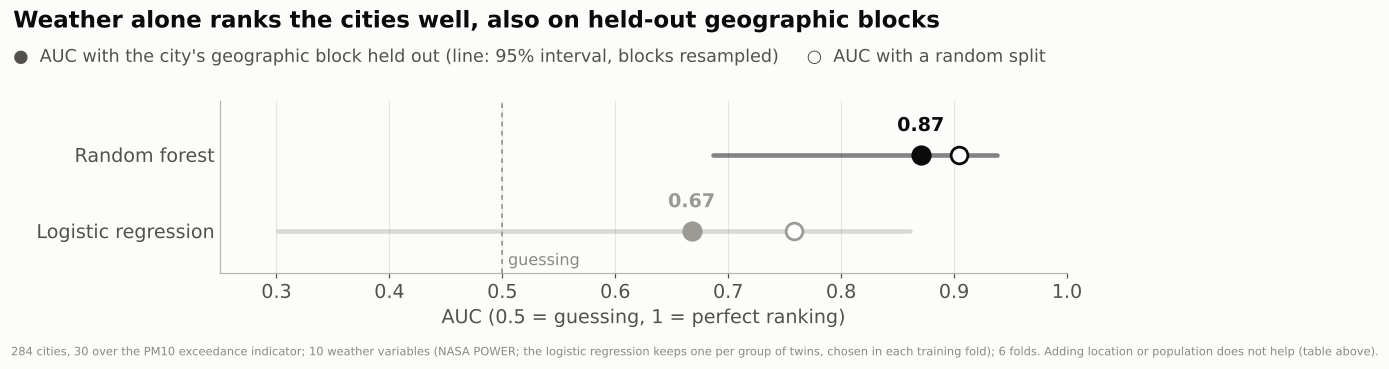

In [10]:
# Shared look of the block C figures: a title that states the message, one grey line saying how to read the figure,
# the source at the bottom; no legend (the reading line replaces it), no frame, larger text for the projector.
def header(fig, title, subtitle, room=0.95):
    """Title and reading line at the top; returns where the axes can start (room = inches left for them)."""
    h = fig.get_figheight()
    fig.text(0.012, 1 - 0.12 / h, title, fontsize=15, fontweight="bold", color=INK, ha="left", va="top")
    fig.text(0.012, 1 - 0.47 / h, subtitle, fontsize=11.5, color=INK_2, ha="left", va="top")
    return 1 - room / h

def clean(ax, grid_x=True):
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=grid_x)

# Figure C1: how well each weather-only model ranks cities it was not trained on
with plt.rc_context({"font.size": 12.5}):
    fig, ax = plt.subplots(figsize=(10, 3.3))
    m1 = results[results["predictors"] == "M1 weather"].set_index(["model", "cross-validation"])
    order = ["Logistic regression", "Random forest"]                            # best model on top
    for row, model in enumerate(order):
        g, r = m1.loc[(model, "geographic")], m1.loc[(model, "random")]
        colour = INK if model == "Random forest" else "#9b9a95"
        ax.plot([g["AUC 95% low"], g["AUC 95% high"]], [row, row], color=colour, linewidth=3, solid_capstyle="round",
                alpha=0.35 if model != "Random forest" else 0.5)
        ax.scatter(r["AUC"], row, s=120, facecolor="white", edgecolor=colour, linewidth=1.8, zorder=3)
        ax.scatter(g["AUC"], row, s=150, color=colour, zorder=4)
        ax.text(g["AUC"], row + 0.25, f"{g['AUC']:.2f}", ha="center", va="bottom", color=colour, fontweight="bold")
    ax.axvline(0.5, color=MUTED, linestyle=(0, (3, 3)), linewidth=1)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlim(0.25, 1.0)                          # the logistic regression interval reaches 0.30
    ax.text(0.505, -0.5, "guessing", color=MUTED, fontsize=10.5, va="bottom")
    ax.set_ylim(-0.55, len(order) - 0.3)
    ax.set_xlabel("AUC (0.5 = guessing, 1 = perfect ranking)")
    clean(ax)
    top = header(fig, "Weather alone ranks the cities well, also on held-out geographic blocks",
                 "●  AUC with the city's geographic block held out (line: 95% interval, blocks resampled)     ○  AUC with a random split")
    fig.subplots_adjust(left=0.2, right=0.97, top=top, bottom=0.24)
    source(fig, f"{len(cities)} cities, {y.sum()} over the PM10 exceedance indicator; 10 weather variables (NASA POWER; the logistic regression keeps one per group of twins, chosen in each training fold); 6 folds. "
                "Adding location or population does not help (table above).")
    fig.savefig("../figures/C1_model_comparison.png", bbox_inches="tight")
    plt.show()

How to read it: one row per model, both with the weather variables only. Filled dot = AUC when the city's geographic block is held out, with its 95% interval as a bar; ring = AUC with a random split. The random forest, used in the rest of the notebook, is in black; the logistic regression in grey. The models with location and population are in the table above: they add nothing, so they are not drawn. The gap between ring and dot is a rough indication of how much the random score is helped by neighbouring cities, not an exact measure.

- **The forest is clearly above the baseline, the logistic regression is not.** With the 12 blocks resampled, every forest interval stays well above 0.5; every logistic regression interval includes 0.5 (weather only, geographic: 0.67 [0.30–0.86]). With 30 cities over the limit, 17 of them in one block, an AUC of 0.67 can come from luck.
- **The weather-only forest has a geographic AUC of 0.87 [0.69–0.94] and an average precision of 0.39**, almost four times the 0.106 of a model with no skill. The interval is wide because the 30 cities over the limit sit in few blocks; resampling single cities, as if they were independent, would give 0.81–0.92, too narrow.
- **The random forest is the best model, and M1 and M2 are practically tied**: geographic AUC 0.8705 with weather only (M1) and 0.8710 with location added (M2); random AUC 0.90 for both. We **choose M1** for the following sections because it is simpler (10 variables instead of 12) and has a better balanced accuracy at 0.5 (0.74 against 0.73 geographic; 17 against 16 cities flagged). It is a motivated choice between results that are essentially the same, not a clear win.
- **Recall depends on the threshold, AUC does not.** At 0.5 the forest flags 17 of the 30 cities (0.57 geographic) and the logistic regression 19 (0.63), although the forest ranks the cities much better: many forest scores sit just above or below 0.5. AUC is the main result; the errors at 0.5 are in the next table.
- **The logistic regression is the weaker model** (AUC 0.76 random, 0.67 geographic) and loses more with the geographic split. It adds up the variables along one straight boundary, while the cities over the limit have two different kinds of weather (section 4): still air in the Po Valley, normal wind but cold winters in Poland. A plausible reason is that one straight boundary cannot hold both, while the forest can draw any shape; the comparison does not isolate the reason, though (the forest also uses 10 variables, the logistic regression 5).
- **Location adds nothing measurable** (M2 ≈ M1 for every model). **Population does not help, and the forest gets a little worse with it** on held-out blocks: geographic AUC 0.83 instead of 0.87, a difference between 0.003 and 0.07 in the paired bootstrap over the blocks (next cells). The large drop in balanced accuracy (0.54, only 4 of the 30 found) is mostly the threshold: with population, the forest gives a score of 0.5 or more to only 16 cities.

So: **weather alone ranks the cities as well as anything we have**, and adding location or population does not improve the prediction. This is about prediction: it does not say that the city (traffic, industry, emissions, which are not in the data) does not matter. The following sections use the weather-only forest (M1).

> ✅ **CHECKPOINT 5 — models compared.** Best: random forest on weather (AUC 0.87 [0.69–0.94] geographic, blocks resampled; average precision 0.39). Logistic regression weakest; its interval includes 0.5. Location adds nothing; population does not help. Model outputs are scores for ranking, not probabilities.

## 6. Random forest: which weather it needs

**Permutation importance**: on the cities of a held-out fold of the **random** cross-validation, shuffle one variable (so it carries no information any more) and measure how much the AUC drops. A large drop = the forest needs that variable, *given all the others*. Random folds are used here because some geographic folds contain no city over the limit, where the AUC cannot be computed. It is computed on held-out folds, never on the training data, where a deep forest seems to need everything because it has memorised everything. The forest's built-in importance (`feature_importances_`) is not used: it is computed on the training data and favours variables with many possible split points.

Two cautions for the reading: an importance near zero means "not needed, given the others", not "not related"; and twins (wind and winter wind) share the credit, so each can look less important than the information it carries.

Because of the twins, the importance is also measured for **families** of variables shuffled together, with the same shuffle for every column of the family: the two winds (yearly and winter), and the temperature family (yearly and winter temperature, frost days, winter mixing layer). A family shuffled together loses all its information at once, so its drop in AUC shows what the forest loses when no variable of that kind is left.

,median,Q1,Q3
family,,,
Wind (year + winter),0.205,0.129,0.272
Temperature family,0.110,-0.014,0.213
Humidity,0.014,0.000,0.028
Rain (log),0.000,-0.005,0.010
Solar radiation,-0.002,-0.014,0.007
Day–night range,-0.005,-0.010,0.005


,median,Q1,Q3
variable,,,
Wind (year),0.057,0.016,0.090
Winter wind,0.029,0.010,0.042
Humidity,0.014,0.000,0.024
Temperature (year),0.014,-0.010,0.051
Winter temperature,0.005,-0.025,0.037
Frost days,0.005,-0.005,0.019
"Mixing layer, winter (rough)",0.005,-0.005,0.009
Rain (log),0.000,-0.009,0.014
Day–night range,-0.005,-0.011,0.005


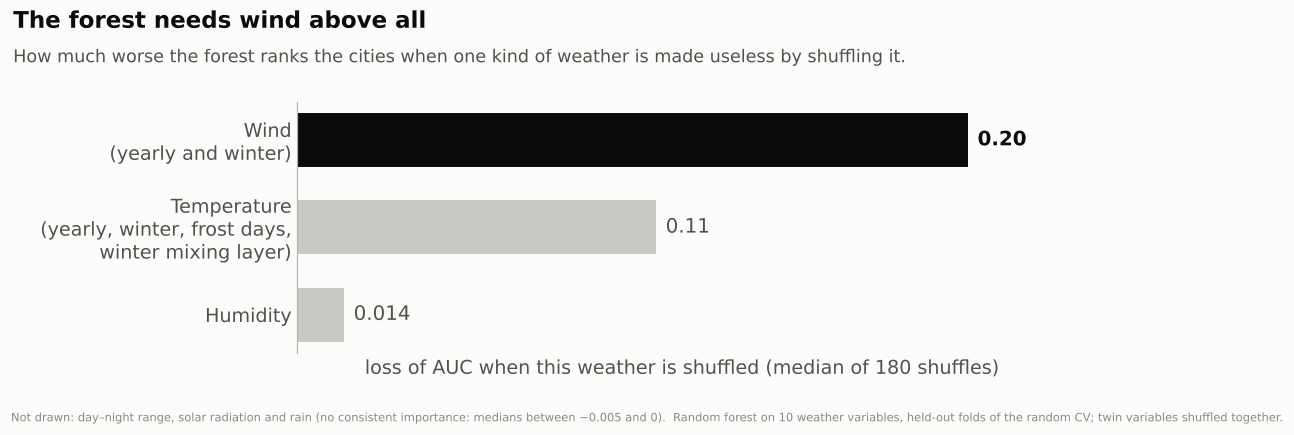

In [11]:
# Permutation importance of the weather-only forest on the held-out folds of the random CV:
# single variables (scikit-learn) and families of twins shuffled together (same row permutation for all their columns)
FAMILIES = {"Wind (year + winter)": ["wind", "wind_winter"],
            "Temperature family": ["temperature", "temperature_winter", "frost_days_year", "mixing_layer_winter_m"],
            "Humidity": ["humidity"], "Rain (log)": ["log_rain_mm_day"], "Day–night range": ["diurnal_range"],
            "Solar radiation": ["solar_radiation"]}
rng = np.random.default_rng(SEED)
rows, family_rows = [], []
for fold, (train, test) in enumerate(random_cv.split(cities, y)):
    model = forest().fit(cities.iloc[train][WEATHER], y.iloc[train])
    X_test, y_test = cities.iloc[test][WEATHER], y.iloc[test]
    result = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
    for j, var in enumerate(WEATHER):
        rows += [{"variable": LABELS[var], "fold": fold, "drop in AUC": d} for d in result.importances[j]]
    base = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    for family, columns in FAMILIES.items():
        for _ in range(30):
            shuffled = X_test.copy()
            shuffled[columns] = shuffled[columns].to_numpy()[rng.permutation(len(shuffled))]
            family_rows.append({"family": family, "fold": fold,
                                "drop in AUC": base - roc_auc_score(y_test, model.predict_proba(shuffled)[:, 1])})
importance, family_importance = pd.DataFrame(rows), pd.DataFrame(family_rows)
order = importance.groupby("variable")["drop in AUC"].median().sort_values()
family_order = family_importance.groupby("family")["drop in AUC"].median().sort_values()

def quartiles(table, key, index):
    return (table.groupby(key)["drop in AUC"].describe()[["50%", "25%", "75%"]]
            .rename(columns={"50%": "median", "25%": "Q1", "75%": "Q3"}).loc[index[::-1]])
display(show(quartiles(family_importance, "family", family_order.index), 3))
display(show(quartiles(importance, "variable", order.index), 3))

# Figure C2: what the forest needs. Only the kinds of weather whose loss is not zero are drawn; the others are named
# in the caption (a sentence instead of empty rows: lecture 3c, "too few data → a sentence")
with plt.rc_context({"font.size": 12.5}):
    fam = family_importance.groupby("family")["drop in AUC"].median().sort_values()
    needed, not_needed = fam[fam >= 0.005], fam[fam < 0.005]
    names = {"Wind (year + winter)": "Wind\n(yearly and winter)",
             "Temperature family": "Temperature\n(yearly, winter, frost days,\nwinter mixing layer)",
             "Humidity": "Humidity"}
    fig, ax = plt.subplots(figsize=(10, 3.9))
    for row, (name, value) in enumerate(needed.items()):
        best = row == len(needed) - 1
        ax.barh(row, value, height=0.62, color=INK if best else "#c9c8c3")
        ax.text(value + 0.003, row, f"{value:.2f}" if value >= 0.02 else f"{value:.3f}", va="center",
                color=INK if best else INK_2, fontweight="bold" if best else "normal", fontsize=13)
    ax.set_yticks(range(len(needed)), [names.get(n, n) for n in needed.index])
    ax.set_xlim(0, 0.235)
    ax.set_xlabel("loss of AUC when this weather is shuffled (median of 180 shuffles)")
    clean(ax, grid_x=False)
    ax.spines["bottom"].set_visible(False)
    ax.set_xticks([])
    top = header(fig, "The forest needs wind above all",
                 "How much worse the forest ranks the cities when one kind of weather is made useless by shuffling it.")
    fig.subplots_adjust(left=0.27, right=0.97, top=top, bottom=0.17)
    plain = {"Rain (log)": "rain", "Solar radiation": "solar radiation", "Day–night range": "day–night range"}
    rest = [plain.get(n, n) for n in not_needed.index]
    rest_text = (", ".join(rest[:-1]) + " and " + rest[-1]) if len(rest) > 1 else "".join(rest)
    source(fig, f"Not drawn: {rest_text} (no consistent importance: medians between −0.005 and 0). "
                " Random forest on 10 weather variables, held-out folds of the random CV; "
                "twin variables shuffled together.")
    fig.savefig("../figures/C2_permutation_importance.png", bbox_inches="tight")
    plt.show()

The forest needs **wind** above all: shuffling the two winds together lowers the AUC by about **0.20** (median of 180 shuffles), by far the largest loss. The temperature family comes second (about 0.11, but with a wide spread: in some folds the forest can do without it, see Q1–Q3 in the table), humidity third (0.014). Rain, day–night range and solar radiation show no consistent importance, given the others (medians between −0.005 and 0). This measures what this forest relies on, not a causal effect of the weather on pollution.

The second table shows why the families are needed: shuffled one at a time, the yearly wind costs only 0.057 and the winter wind 0.029, because while one is shuffled its twin still carries the information. The 180 values of each row are not 180 independent samples (they share the same 6 fitted forests), so Q1–Q3 show the spread of the procedure, not a confidence interval. Figure C2 shows only the medians of the families that matter: one bar per kind of weather. Rain, solar radiation and day–night range are not drawn, because they show no consistent loss (medians between −0.005 and 0): the caption says so.

> ✅ **CHECKPOINT 6 — what the forest needs.** Wind first: about 0.20 of AUC lost when both winds are shuffled together (0.057 and 0.029 one at a time). Then the temperature family, then humidity a little; rain, day–night range and sun: no consistent importance.

## 7. Which cities the model gets wrong, and how strict the test is

We take the best model of section 5 that uses weather only (random forest, M1) and its predictions with the **geographic** cross-validation: every city is scored by a model not trained on its geographic block. Threshold 0.5.

In [12]:
# Outcome of every city with the weather-only forest, geographic CV, threshold 0.5
p_geo = probabilities[("M1 weather", "Random forest", "geographic")]
score_random = probabilities[("M1 weather", "Random forest", "random")]
cities["score_random"], cities["score_geographic"] = score_random, p_geo
cities["outcome"] = np.select(
    [(y == 1) & (p_geo >= 0.5), (y == 1) & (p_geo < 0.5), (y == 0) & (p_geo >= 0.5)],
    ["over the limit, predicted", "over the limit, missed", "false alarm"], "under the limit, predicted")

matrix = pd.DataFrame(confusion_matrix(y, p_geo >= 0.5), index=["really under", "really over"],
                      columns=["predicted under", "predicted over"])
display(show(matrix, 0))
display(show(pd.crosstab(cities["outcome"], cities["group"])[GROUP_ORDER], 0))
missed = cities[cities["outcome"] == "over the limit, missed"].sort_values("score_geographic")
show(missed.set_index("city")[["country", "group", "score_geographic", "score_random", "wind_winter", "temperature_winter"]])

,predicted under,predicted over
really under,234,20
really over,13,17


group,Po Valley,Poland,Rest of Europe
outcome,,,
false alarm,6,0,14
"over the limit, missed",1,8,4
"over the limit, predicted",16,0,1
"under the limit, predicted",2,24,208


,country,group,score_geographic,score_random,wind_winter,temperature_winter
city,,,,,,
Zagreb,HR,Rest of Europe,0.05,0.04,3.17,2.68
A Coruña,ES,Rest of Europe,0.06,0.07,3.73,10.18
Rybnik,PL,Poland,0.16,0.35,4.66,0.40
Kraków,PL,Poland,0.16,0.30,4.49,0.38
Zabrze,PL,Poland,0.17,0.90,4.84,0.49
Katowice,PL,Poland,0.17,0.88,4.84,0.49
Legnica,PL,Poland,0.19,0.14,5.43,0.92
Radom,PL,Poland,0.20,0.36,4.91,0.12
Piotrków Trybunalski,PL,Poland,0.26,0.48,5.04,0.22


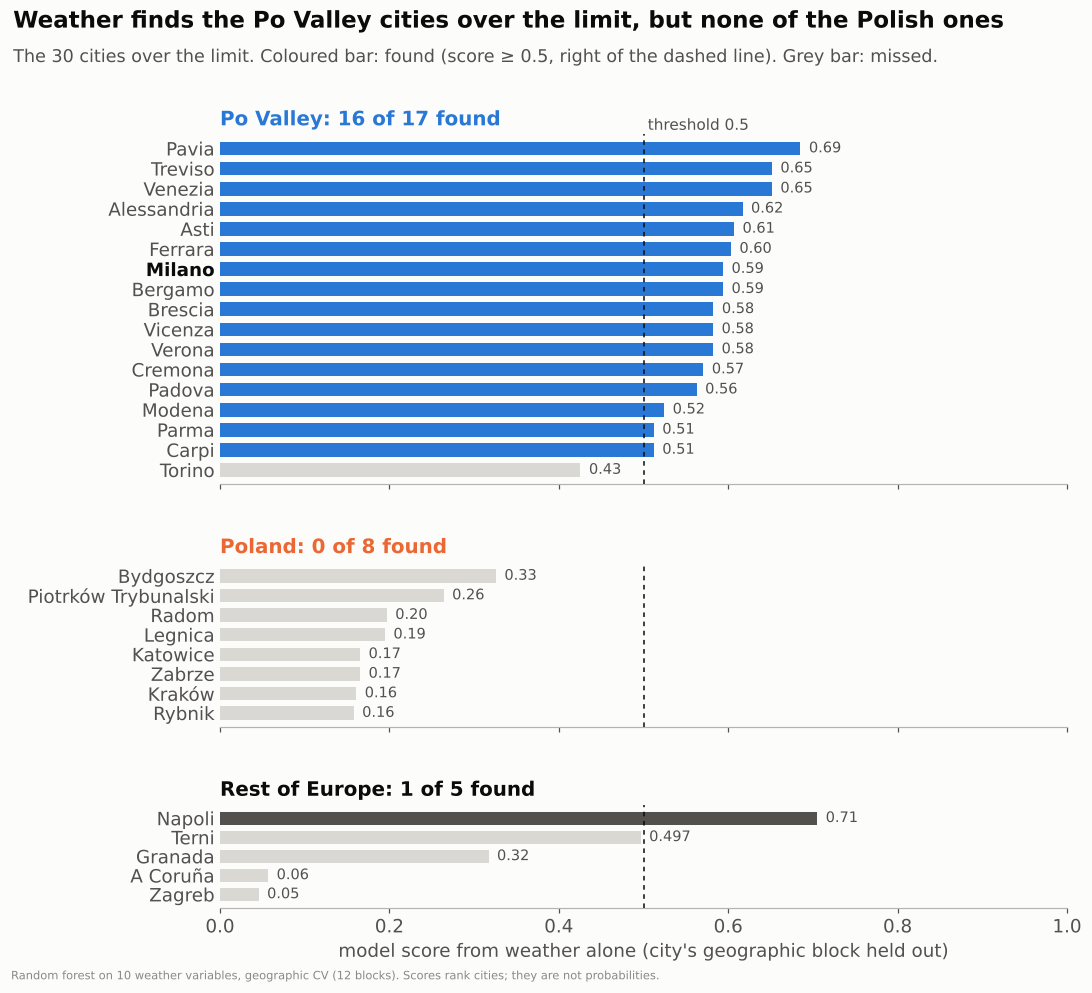

In [13]:
# Figure C3: the 30 cities over the limit and their score (geographic CV), one panel per group, threshold 0.5.
# One bar per city, starting next to its name: the score has a real zero, so a bar from 0 is honest.
# Coloured bar = found (score >= 0.5), grey bar = missed; the value is written at the end of each bar.
with plt.rc_context({"font.size": 12}):
    over = cities[y == 1].copy()
    over["name"] = over["city"].str.replace(" (greater city)", "", regex=False)
    groups = [(g, over[over["group"] == g].sort_values("score_geographic")) for g in GROUP_ORDER]
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True,
                             gridspec_kw={"height_ratios": [len(p) for _, p in groups], "hspace": 0.38})
    for ax, (name, part) in zip(axes, groups):
        scores = part["score_geographic"].to_numpy()
        hit = scores >= 0.5
        rows = np.arange(len(part))
        colour = GROUP_COLOURS[name] if name != "Rest of Europe" else INK_2
        ax.barh(rows, scores, height=0.68, color=[colour if h else "#d9d8d3" for h in hit], zorder=2)
        for row, value in zip(rows, scores):
            label = f"{value:.3f}" if abs(value - 0.5) < 0.005 else f"{value:.2f}"   # Terni 0.497 is not 0.50
            ax.text(value + 0.01, row, label, va="center", fontsize=9.5, color=INK_2)
        ax.axvline(0.5, color=INK, linewidth=1, linestyle=(0, (3, 3)), zorder=3)
        ax.set_yticks(rows, part["name"])
        for tick, city in zip(ax.get_yticklabels(), part["city"]):
            if city == milan["city"]:
                tick.set_fontweight("bold")
                tick.set_color(INK)
        ax.set_ylim(-0.7, len(part) - 0.3)
        clean(ax, grid_x=False)
        ax.spines["left"].set_visible(False)
        ax.set_title(f"{name}: {int(hit.sum())} of {len(part)} found", loc="left", fontsize=13, fontweight="bold",
                     color=colour if name != "Rest of Europe" else INK, pad=6)
    axes[0].text(0.505, len(groups[0][1]) - 0.25, "threshold 0.5", color=INK_2, fontsize=10, va="bottom")
    axes[-1].set_xlim(0, 1)
    axes[-1].set_xlabel("model score from weather alone (city's geographic block held out)")
    top = header(fig, "Weather finds the Po Valley cities over the limit, but none of the Polish ones",
                 "The 30 cities over the limit. Coloured bar: found (score ≥ 0.5, right of the dashed line). Grey bar: missed.",
                 room=1.25)
    fig.subplots_adjust(left=0.2, right=0.97, top=top, bottom=0.08)
    source(fig, "Random forest on 10 weather variables, geographic CV (12 blocks). Scores rank cities; they are not probabilities.")
    fig.savefig("../figures/C3_who_the_model_misses.png", bbox_inches="tight")
    plt.show()


Of the 30 cities over the limit, the weather-only forest flags **17** when their geographic block is held out; it misses **13** and raises **20** false alarms.

- **Po Valley**: 16 of 17 flagged (only Torino missed, at 0.43). Three of them are just above the threshold (Modena 0.52, Carpi and Parma 0.51), so the "16" depends on the threshold. Here the block of 24 Po Valley cities is held out, but Torino and the other Italian cities are in training: the next tables test harder cases.
- **Poland: all 8 missed.** The model, with these predictors and this validation, does not identify the Polish cities over the limit. Their weather is close to that of the Polish cities under the limit (median winter wind 4.9 vs 5.0 m/s, winter temperature 0.4 vs 0.6 °C); similar medians do not prove that the two groups cannot be told apart with all the variables together, but this model does not. And when the Polish block is held out, no other block has cold, windy cities over the limit to learn from.
- **Elsewhere**: Napoli flagged; Zagreb, A Coruña and Granada missed (low scores); Terni just below the threshold (0.497).
- **False alarms**: mostly Italian cities outside the Po Valley (Roma, Caserta, Latina, L'Aquila, Firenze, Genova…) and 6 Po Valley cities under the limit (Piacenza, Novara, Forlì…): cities whose weather resembles that of the cities over the limit, but which stay below 35 days.

So the model recognises **weather that looks like that of the cities over the limit**, not exceedance itself.

In [14]:
# A harder test: leave a whole area out at once, train on all the other cities, score the area
AREAS = {"Po Valley": cities["group"] == "Po Valley", "Italy": cities["country"] == "IT", "Poland": cities["group"] == "Poland"}
rows = []
for name, area in AREAS.items():
    area = area.to_numpy()
    model = forest().fit(cities.loc[~area, WEATHER], y[~area])
    score = model.predict_proba(cities.loc[area, WEATHER])[:, 1]
    over = y[area].to_numpy() == 1
    rows.append({"left out of training": f"{name} ({area.sum()} cities)", "over the limit in the area": int(over.sum()),
                 "found": int(((score >= 0.5) & over).sum()), "false alarms": int(((score >= 0.5) & ~over).sum()),
                 "over the limit left for training": int(y[~area].sum())})
show(pd.DataFrame(rows).set_index("left out of training"), 0)

,over the limit in the area,found,false alarms,over the limit left for training
left out of training,,,,
Po Valley (25 cities),17,13,4,13
Italy (57 cities),19,3,10,11
Poland (32 cities),8,0,0,22


**A harder test: whole areas left out.** Here one area at a time is removed completely from training, and the forest trained on all the other cities scores it. These are three different test populations, and they show the limits of transfer from one area to another:

- **Po Valley left out (25 cities): 13 of 17 found.** Without any Po Valley city, the model still recognises most of them, learning from the other Italian cities over the limit (Napoli, Terni) and from the rest.
- **Italy left out (57 cities): 3 of 19 found.** With no Italian city in training, only 11 cities over the limit are left to learn from (8 Polish, 3 others), and the model does not recognise the Italian pattern.
- **Poland left out (32 cities): 0 of 8 found**, and no false alarm: trained on the rest of Europe, the model does not identify the Polish cities over the limit.

So the Po Valley pattern is recognised when similar cities are in training, not from any part of Europe; the Polish cities over the limit are not identified in any of the tests.

The next cells go one step further: how much of the Po Valley result comes from Torino alone, what happens with one whole country left out at a time, and whether a model that knows only the coordinates would do as well.

In [15]:
# Stricter tests. (a) The fold of the geographic CV that holds the Italian block: what does the model see in training?
po_block = pd.Series(blocks[cities["po_valley"].values]).mode()[0]       # the block holding most Po Valley cities
po_fold = np.zeros(len(cities), dtype=bool)
for train, test in geographic_cv.split(cities, y, blocks):
    if po_block in set(blocks[test]):
        po_fold[test] = True
        seen = cities.iloc[train][y.iloc[train] == 1]
        print(f"Fold with the Italian block: {len(seen)} cities over the limit in training:")
        print("   ", ", ".join(f"{c} ({g})" for c, g in zip(seen["city"].str.replace(" (greater city)", ""), seen["group"])))

# (b) Hold-out tests on the Po Valley cities over the limit: with and without Torino in training, whole Po Valley, whole Italy
def hold_out(hidden, drop_from_training=()):
    train = ~hidden & ~cities["city"].isin(drop_from_training).values
    model = forest().fit(cities.loc[train, WEATHER], y[train])
    return model.predict_proba(cities.loc[hidden, WEATHER])[:, 1]

po_valley, italy = cities["po_valley"].values, (cities["country"] == "IT").values
HOLD_OUTS = {"12 blocks: Italian block hidden\n(Torino in training)": (po_fold, ()),
             "same, Torino removed\nfrom training": (po_fold, ("Torino",)),
             "all 25 Po Valley cities hidden\n(Terni, Napoli in training)": (po_valley, ()),
             "all 57 Italian cities hidden": (italy, ())}
rows = []
for name, (hidden, dropped) in HOLD_OUTS.items():
    p = hold_out(hidden, dropped)
    over_po = ((y[hidden] == 1) & po_valley[hidden]).to_numpy()
    rows.append({"test": name, "Po Valley cities over the limit hidden": over_po.sum(),
                 "flagged (score ≥ 0.5)": ((p >= 0.5) & over_po).sum(), "median score": np.median(p[over_po])})
hold_outs = pd.DataFrame(rows).set_index("test")
display(show(hold_outs.rename(index=lambda s: s.replace("\n", " ")), 2))

# (c) Weather against coordinates, from the easiest to the hardest split (one country left out = LeaveOneGroupOut)
SPLITS = {"random": (random_cv, None), "12 geographic blocks": (geographic_cv, blocks),
          "one country left out": (LeaveOneGroupOut(), cities["country"].values)}
strictness = pd.DataFrame({name: {split: roc_auc_score(y, cross_val_predict(forest(), cities[columns], y, cv=cv,
                                                                             groups=groups, method="predict_proba")[:, 1])
                                  for split, (cv, groups) in SPLITS.items()}
                           for name, columns in [("weather (M1)", WEATHER), ("latitude and longitude only", ["lat", "lon"])]}).T
display(show(strictness, 2))

# (d) Inside Poland: do the geographic scores separate the Polish cities over and under the limit?
poland = (cities["group"] == "Poland").values
auc_poland = roc_auc_score(y[poland], cities.loc[poland, "score_geographic"])
print(f"AUC among the {poland.sum()} Polish cities only (geographic scores): {auc_poland:.2f}")

# (e) Cities with identical weather values (same NASA POWER cell): near-copies in a random split
same_weather = cities[WEATHER].round(6).duplicated(keep=False)
twins = (cities[same_weather].groupby(cities.loc[same_weather, WEATHER].round(6).apply(tuple, axis=1))["city"]
         .apply(lambda s: ", ".join(s.str.replace(" (greater city)", ""))))
print(f"\n{same_weather.sum()} cities share all 10 weather values with at least one other city ({len(twins)} groups):")
print("   " + "; ".join(twins))

Fold with the Italian block: 13 cities over the limit in training:
    A Coruña (Rest of Europe), Granada (Rest of Europe), Zagreb (Rest of Europe), Napoli (Rest of Europe), Torino (Po Valley), Bydgoszcz (Poland), Katowice (Poland), Kraków (Poland), Legnica (Poland), Piotrków Trybunalski (Poland), Radom (Poland), Rybnik (Poland), Zabrze (Poland)


,Po Valley cities over the limit hidden,flagged (score ≥ 0.5),median score
test,,,
12 blocks: Italian block hidden (Torino in training),16,16,0.59
"same, Torino removed from training",16,3,0.40
"all 25 Po Valley cities hidden (Terni, Napoli in training)",17,13,0.56
all 57 Italian cities hidden,17,2,0.44


,random,12 geographic blocks,one country left out
weather (M1),0.90,0.87,0.65
latitude and longitude only,0.83,0.77,0.45


AUC among the 32 Polish cities only (geographic scores): 0.46

41 cities share all 10 weather values with at least one other city (20 groups):
   Gdansk, Gdynia; Friedrichshafen, Konstanz; Katowice, Zabrze; Winterthur, Zürich; Genève, Annemasse; Mainz, Wiesbaden; Ludwigsburg, Stuttgart; Berlin, Potsdam; Heidelberg, Mannheim; Frankfurt am Main, Hanau; Pavia, Piacenza; Verona, Vicenza; Genova, Savona; Modena, Reggio nell'Emilia, Sassuolo; Madrid, Torrejón de Ardoz; Bergamo, Milano; Gijón, Oviedo; Carpi, Parma; Treviso, Venezia; Alcoy, Elda


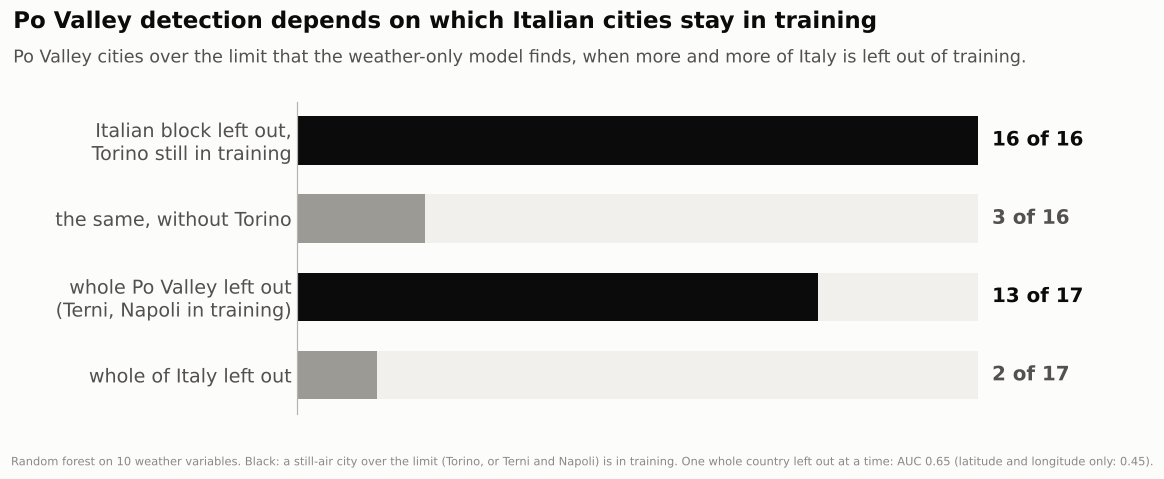

In [16]:
# Figure C4: how strict is the test? Po Valley cities over the limit flagged, in four tests from easy to hard
with plt.rc_context({"font.size": 12.5}):
    fig, ax = plt.subplots(figsize=(10, 4.3))
    tests = hold_outs.iloc[::-1]
    labels = {"12 blocks: Italian block hidden\n(Torino in training)": "Italian block left out,\nTorino still in training",
              "same, Torino removed\nfrom training": "the same, without Torino",
              "all 25 Po Valley cities hidden\n(Terni, Napoli in training)": "whole Po Valley left out\n(Terni, Napoli in training)",
              "all 57 Italian cities hidden": "whole of Italy left out"}
    for row, (test, r) in enumerate(tests.iterrows()):
        n, k = int(r["Po Valley cities over the limit hidden"]), int(r["flagged (score ≥ 0.5)"])
        seen = "without" not in labels[test] and "Italy" not in labels[test]
        ax.barh(row, 1, height=0.62, color="#f1f0ec")                           # the whole: all the hidden cities
        ax.barh(row, k / n, height=0.62, color=INK if seen else "#9b9a95")
        ax.text(1.02, row, f"{k} of {n}", va="center", fontweight="bold", color=INK if seen else INK_2, fontsize=13)
    ax.set_yticks(range(len(tests)), [labels[t] for t in tests.index])
    ax.set_xlim(0, 1.13)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    clean(ax, grid_x=False)
    top = header(fig, "Po Valley detection depends on which Italian cities stay in training",
                 "Po Valley cities over the limit that the weather-only model finds, when more and more of Italy is left out of training.")
    fig.subplots_adjust(left=0.27, right=0.97, top=top, bottom=0.12)
    source(fig, "Random forest on 10 weather variables. Black: a still-air city over the limit (Torino, or Terni and Napoli) is in training. "
                f"One whole country left out at a time: AUC {strictness.loc['weather (M1)', 'one country left out']:.2f} "
                f"(latitude and longitude only: {strictness.loc['latitude and longitude only', 'one country left out']:.2f}).")
    fig.savefig("../figures/C4_how_strict_is_the_test.png", bbox_inches="tight")
    plt.show()

**Even stricter tests** (tables above and figure C4):

- **Weather beats a coordinates-only model**: in every split it ranks the cities better than latitude and longitude alone (0.87 against 0.77 with the 12 blocks; 0.65 against 0.45 with one country left out, where coordinates do worse than chance because a forest cannot extrapolate to a country it has not seen). This shows that the weather model beats this coordinates-only model, not that the weather carries no geographic information.
- **But the Po Valley result depends on which Italian cities stay in training.** With Torino in training, all 16 Po Valley cities over the limit of the Italian block are flagged; **without Torino, 3 of 16**. With all 25 Po Valley cities hidden, 13 of 17 are still flagged, because Terni and Napoli (still air, over the limit) are in training. With the whole of Italy hidden, **2 of 17** Po Valley cities (3 of the 19 Italian cities over the limit). With one country left out at a time, the AUC falls from 0.87 to **0.65**.
- **Why**: in our data, outside Italy no city combines still air and exceedances. A forest cannot extrapolate: if no city with Po Valley weather is over the limit in training, it has no reason to give that weather a high score. The still air of the Po Valley is unusual in Europe (Milan is at the 2nd percentile for winter wind, notebook 02), so the rest of Europe cannot teach it.
- **Poland is a different failure**: Legnica (over the limit, in another block) is in training when the other Polish cities are scored, and still, among the 32 Polish cities, the scores do not separate those over and under the limit (AUC 0.46, chance level).
- **41 cities share identical weather values** with another city: one more reason why the random CV (where the twin is often in training) is too optimistic.

So the result is stated carefully: **the model recognises the Po Valley type of exceedance when similar Italian cities are in training; from the rest of Europe alone it does not.** The 0.87 of section 5 is the score with 12 geographic blocks; with whole countries hidden it is 0.65.

> ✅ **CHECKPOINT 7 — errors understood.** At 0.5: Po Valley 16/17 with block 5 held out, but 3/16 once Torino is removed from training, 13/17 with the whole Po Valley out, 3/19 Italian cities with all of Italy out; one country left out: AUC 0.65, still above coordinates (0.45). Poland 0/8, and chance level inside Poland (AUC 0.46). False alarms are cities with similar weather that stay under the limit.

## 8. Final link: the predictions by cluster of block B

The question of the project, in one table: for which type of city does the weather predict the exceedance indicator? We take the scores of the weather-only forest with the **geographic** cross-validation (every city scored by a model not trained on its geographic block; `out_of_fold` of `src/validation.py`, same splits as section 7) and group them by the four clusters of notebook 03 (k = 4). The clusters are used only here, to group the predictions, never inside the model. Both the clusters and the target come from the pollution of the same cities, so this is a descriptive comparison, not an independent validation.

In [17]:
# Geographic out-of-fold scores from the shared function of src/validation.py (same splits as section 7)
p_link = shared_out_of_fold(forest(), cities[WEATHER], y, blocks, method="predict_proba")
assert np.allclose(p_link, cities["score_geographic"])

link = cities.assign(predicted_over=p_link >= 0.5, hit=(p_link >= 0.5) & (y == 1), p=p_link)
link["cluster"] = link["cluster_k4"].astype(int).astype(str) + "  " + link["cluster_k4_name"]
by_cluster = link.groupby("cluster").agg(cities=("city", "size"), over_the_limit=("exceeds_pm10_limit", "sum"),
                                         predicted_over=("predicted_over", "sum"), over_and_found=("hit", "sum"),
                                         mean_score=("p", "mean"))
by_cluster["recall"] = (by_cluster["over_and_found"] / by_cluster["over_the_limit"]).where(by_cluster["over_the_limit"] > 0)
table = by_cluster.assign(recall=by_cluster["recall"].map(lambda v: f"{v:.2f}" if pd.notna(v) else "no city over"))
display(show(table.rename(columns=lambda c: c.replace("_", " ")), 2))

# The cities over the limit of each smog cluster, with their score
for number in (1, 2):
    over = link[(link["cluster_k4"] == number) & (y == 1)].sort_values("p", ascending=False)
    print(f"Cluster {number}:", ", ".join(f"{c} {p:.2f}" for c, p in zip(over["city"], over["p"])))

# Milan inside its cluster
same = link[link["cluster_k4"] == milan["cluster_k4"]].sort_values("p", ascending=False).reset_index(drop=True)
rank = same.index[same["city"] == milan["city"]][0] + 1
print(f"Milan: score {p_link[milan.name]:.2f}, rank {rank} of {len(same)} in cluster {int(milan['cluster_k4'])} "
      f"({milan['cluster_k4_name']}); cluster median {same['p'].median():.2f}")

# Inside the stagnant-smog cluster: do the scores separate its cities over and under the limit?
stagnant = (link["cluster_k4"] == 1).values
print(f"Stagnant-smog cluster: median score {np.median(p_link[stagnant & (y == 1).values]):.2f} for the cities over the "
      f"limit, {np.median(p_link[stagnant & (y == 0).values]):.2f} for those under it")

,cities,over the limit,predicted over,over and found,mean score,recall
cluster,,,,,,
1 Stagnant winter smog,27,17,22,16,0.52,0.94
2 Cold-winter particle smog,42,13,5,1,0.25,0.08
"3 Moderate, flat year",126,0,6,0,0.10,no city over
4 Clean background,89,0,4,0,0.11,no city over


Cluster 1: Pavia 0.69, Venezia 0.65, Treviso 0.65, Alessandria 0.62, Asti 0.61, Ferrara 0.60, Milano (greater city) 0.59, Bergamo 0.59, Brescia 0.58, Vicenza 0.58, Verona 0.58, Cremona 0.57, Padova 0.56, Modena 0.52, Carpi 0.51, Parma 0.51, Torino 0.43
Cluster 2: Napoli (greater city) 0.71, Terni 0.50, Bydgoszcz 0.33, Granada 0.32, Piotrków Trybunalski 0.26, Radom 0.20, Legnica 0.19, Zabrze 0.17, Katowice 0.17, Kraków 0.16, Rybnik 0.16, A Coruña 0.06, Zagreb 0.05
Milan: score 0.59, rank 9 of 27 in cluster 1 (Stagnant winter smog); cluster median 0.58
Stagnant-smog cluster: median score 0.58 for the cities over the limit, 0.52 for those under it


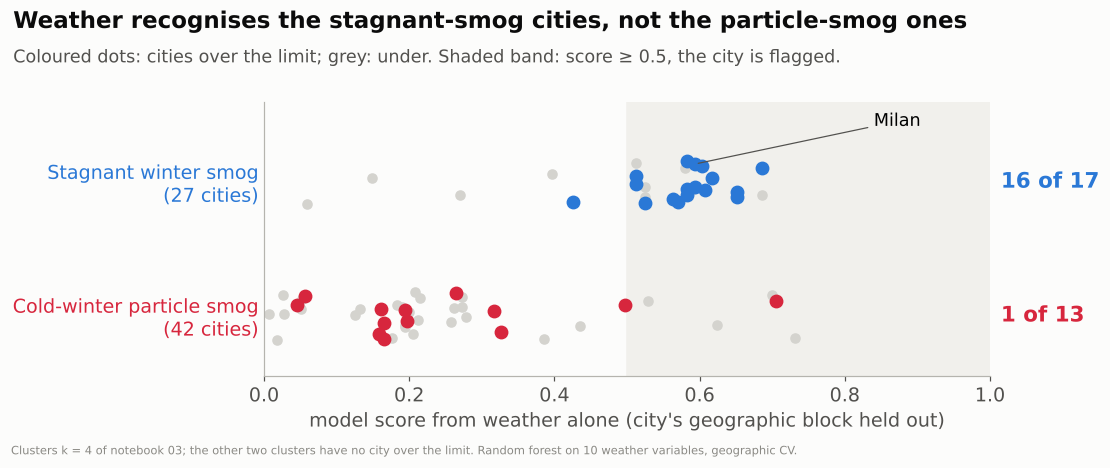

In [18]:
# Figure C5: the two smog clusters of notebook 03 and the weather-only score of each of their cities
with plt.rc_context({"font.size": 12.5}):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    rng = np.random.default_rng(SEED)
    ax.axvspan(0.5, 1, color="#f1f0ec", zorder=0)
    names = link.drop_duplicates("cluster_k4").set_index("cluster_k4")["cluster_k4_name"]
    for row, number in enumerate((2, 1)):                                      # cluster 1 on top
        part = link[link["cluster_k4"] == number]
        jitter = rng.uniform(-0.18, 0.18, len(part))
        over = part["exceeds_pm10_limit"].to_numpy().astype(bool)
        ax.scatter(part["p"][~over], row + jitter[~over], s=35, color="#d4d3ce", zorder=2)
        ax.scatter(part["p"][over], row + jitter[over], s=65, color=CLUSTER_COLOURS[4][number - 1], zorder=3)
        found, total = int((part["p"][over] >= 0.5).sum()), int(over.sum())
        ax.text(1.015, row, f"{found} of {total}", va="center", fontweight="bold", fontsize=14,
                color=CLUSTER_COLOURS[4][number - 1], transform=ax.get_yaxis_transform())
        if number == milan["cluster_k4"]:
            m = jitter[np.where(part.index == milan.name)[0][0]]
            ax.annotate("Milan", (p_link[milan.name], row + m), xytext=(0.84, row + 0.42), ha="left", fontsize=11.5,
                        arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.8))
    ax.set_yticks([0, 1], [f"{names[2]}\n({(link['cluster_k4'] == 2).sum()} cities)",
                           f"{names[1]}\n({(link['cluster_k4'] == 1).sum()} cities)"])
    for tick, number in zip(ax.get_yticklabels(), (2, 1)):
        tick.set_color(CLUSTER_COLOURS[4][number - 1])
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.45, 1.6)
    ax.set_xlabel("model score from weather alone (city's geographic block held out)")
    clean(ax, grid_x=False)
    top = header(fig, "Weather recognises the stagnant-smog cities, not the particle-smog ones",
                 "Coloured dots: cities over the limit; grey: under. Shaded band: score ≥ 0.5, the city is flagged.")
    fig.subplots_adjust(left=0.24, right=0.9, top=top, bottom=0.18)
    source(fig, "Clusters k = 4 of notebook 03; the other two clusters have no city over the limit. Random forest on 10 weather variables, "
                "geographic CV.")
    fig.savefig("../figures/C5_weather_by_cluster.png", bbox_inches="tight")
    plt.show()

What we see, cluster by cluster (threshold 0.5):

- **1 Stagnant winter smog: 16 of 17 flagged** (recall 0.94, mean score 0.52). Only Torino is missed (0.43). The 17 scores come from different folds: 16 from the fold where block 5 is held out, Torino from the fold of block 2. Inside the cluster the scores of the cities over and under the limit overlap (medians 0.58 and 0.52): the model recognises the *type* of city more than which member of it exceeds; the 6 false alarms of this cluster are cities with the same kind of weather that stay under 35 days.
- **2 Cold-winter particle smog: 1 of 13 flagged** (recall 0.08, mean score 0.25). The only one is Napoli (0.71); the 8 Polish cities over the limit all get 0.33 or less, Terni sits at 0.50 without crossing it.
- **3 Moderate and 4 Clean background:** no city over the limit and mostly low scores; 10 false alarms between them.

The answer, within the limits of these data: **the model recognises the stagnant-smog cities well and transfers poorly to the particle-smog ones.** For the first, the weather of the cities over the limit is distinctive and similar cities are available in training (without Torino in training only 3 of the 16 other Po Valley cities are flagged, and with all of Italy left out only 3 of 19 Italian cities: section 7). For the second, the model, with these predictors and this validation, does not identify the Polish cities over the limit (their median weather is close to that of the Polish cities under it). This points to limits of our predictors and of the transfer between areas; it does not identify, by itself, what causes the difference. A winter source such as domestic heating is a possible explanation that these data cannot test.

**Milan** gets a score of 0.59 (threshold 0.5), close to the median of its cluster, 0.58 (Bergamo has the same score, so its rank is 8th–9th of 27): a typical member of the stagnant-smog cluster. The score is not "59% of Milan's pollution explained by the weather", nor a probability of exceeding the limit next year: it is the output of a classifier on our historical indicator.

> ✅ **CHECKPOINT 8 — final link.** At 0.5: recall 0.94 in the stagnant-smog cluster, 0.08 in the particle-smog cluster (1 of 13). The model recognises the Po Valley profile (when similar Italian cities are in training), not the Polish one. Milan: score 0.59, a typical member of its cluster.

## 9. Output and summary

`classification.csv`: one row per city, with its model scores from the weather-only random forest (`score_random`, `score_geographic`), out of fold, with the random and the geographic cross-validation, the outcome with the geographic one, and the clusters of notebook 03 (k = 2 and k = 4). It is the input of the final link.

`classification_models.csv`: the table of section 5 (every model, set of predictors and cross-validation, with the AUC interval and the average precision). `classification_checks.csv`: the other numbers quoted in the slides (importances, stress tests), in a long format (check, item, n, k, value, low, high). `src/make_numbers.py` reads the three files and writes the block C part of `slides/NUMBERS.md`.

In [19]:
# Save one row per city for the final link
output = cities[["country", "city", "group", "cluster_k2", "cluster_k4", "exceeds_pm10_limit", "score_random", "score_geographic",
                 "outcome"]]
output.to_csv("../data/processed/classification.csv", index=False)
results.to_csv("../data/processed/classification_models.csv", index=False)

checks = []                                     # long format: check, item, n, k, value, low, high
def check(name, item, n=None, k=None, value=None, low=None, high=None):
    checks.append({"check": name, "item": item, "n": n, "k": k, "value": value, "low": low, "high": high})

for table, key, label in [(family_importance, "family", "importance, family"), (importance, "variable", "importance, single")]:
    for item, values in table.groupby(key)["drop in AUC"]:
        check(label, item, value=values.median(), low=values.quantile(0.25), high=values.quantile(0.75))
for test, r in hold_outs.iterrows():
    check("hold-out, Po Valley over the limit flagged", test.replace("\n", " "), n=r["Po Valley cities over the limit hidden"],
          k=r["flagged (score ≥ 0.5)"], value=r["median score"])
for name, r in strictness.iterrows():
    for split, value in r.items():
        check("AUC by split", f"{name} | {split}", value=value)
check("AUC difference, weather only minus with population (geographic)", "random forest", value=auc_difference[0],
      low=auc_difference[1], high=auc_difference[2])
check("AUC among the Polish cities only (geographic scores)", "Poland", n=int(poland.sum()), value=auc_poland)
check("cities with identical weather", "cities", n=int(same_weather.sum()), k=len(twins))
check("mean score vs real share", "weather-only forest, geographic", value=p_m1.mean(), low=y.mean())
pd.DataFrame(checks).to_csv("../data/processed/classification_checks.csv", index=False)
print(output.shape, len(results), len(checks))
display(show(output.sort_values("score_geographic", ascending=False).head(8)))
print("Milan:", output.loc[output["city"] == "Milano (greater city)", ["score_random", "score_geographic", "outcome"]]
      .round(2).to_dict("records")[0])

(284, 9) 12 30


,country,city,group,cluster_k2,cluster_k4,exceeds_pm10_limit,score_random,score_geographic,outcome
221,IT,Roma,Rest of Europe,2,2,False,0.35,0.73,false alarm
192,IT,Caserta,Rest of Europe,2,3,False,0.84,0.73,false alarm
207,IT,Napoli (greater city),Rest of Europe,1,2,True,0.52,0.71,"over the limit, predicted"
203,IT,Latina,Rest of Europe,2,2,False,0.81,0.70,false alarm
158,FR,Pau,Rest of Europe,2,4,False,0.59,0.69,false alarm
211,IT,Pavia,Po Valley,1,1,True,0.58,0.69,"over the limit, predicted"
215,IT,Piacenza,Po Valley,1,1,False,0.96,0.69,false alarm
201,IT,L'Aquila,Rest of Europe,2,4,False,0.40,0.66,false alarm


Milan: {'score_random': 0.95, 'score_geographic': 0.59, 'outcome': 'over the limit, predicted'}


### Summary of block C

<table style="margin-left:0; margin-right:auto">
<tr><th style="text-align:left">Question</th><th style="text-align:left">Answer</th><th style="text-align:left">Evidence</th></tr>
<tr><td style="text-align:left">How well does weather predict the exceedance indicator?</td><td style="text-align:left">Well in ranking: AUC 0.87 [0.69–0.94] with geographic blocks held out (interval: blocks resampled; baseline 0.5); average precision 0.39 (no skill 0.106); at threshold 0.5, 17 of 30 found, 20 false alarms (scikit-learn 1.9.1)</td><td style="text-align:left">Section 5, C1</td></tr>
<tr><td style="text-align:left">How strict is that test?</td><td style="text-align:left">Less than it looks: Torino is in a block west of the Alps, and without it 3 of 16 Po Valley cities are flagged; with one country left out AUC 0.65. Coordinates alone do worse in every split</td><td style="text-align:left">Section 7, C4</td></tr>
<tr><td style="text-align:left">Do location or population improve the prediction?</td><td style="text-align:left">No; with population the forest is a little worse on held-out blocks (AUC 0.83)</td><td style="text-align:left">Section 5, C1</td></tr>
<tr><td style="text-align:left">What does the forest need?</td><td style="text-align:left">Wind: both winds shuffled together cost about 0.20 of AUC; then the temperature family, then a little humidity</td><td style="text-align:left">Section 6, C2</td></tr>
<tr><td style="text-align:left">Where does it fail?</td><td style="text-align:left">Poland (0 of 8; chance level inside Poland, AUC 0.46); and Italy as a whole when no Italian city is in training (3 of 19)</td><td style="text-align:left">Section 7, C3, C4</td></tr>
<tr><td style="text-align:left">For which type of city does it work?</td><td style="text-align:left">Stagnant winter smog (16 of 17 found, when similar Italian cities are in training), not cold-winter particle smog (1 of 13)</td><td style="text-align:left">Section 8, C5</td></tr>
</table>

**The expectations of section 4, checked:**

1. *Winter wind is the key predictor for the Po Valley* — **confirmed for the forest.** Both winds shuffled together cost about 0.20 of AUC; 16 of 17 Po Valley cities over the limit found with their block held out (3 of 16 without Torino in training, 13 of 17 with the whole Po Valley left out).
2. *Winter temperature may catch the Polish-type cities* — **not confirmed.** Temperature is the forest's second need (about 0.11 of AUC), but with geographic blocks left out 0 of the 8 Polish cities over the limit are found, and inside Poland the scores are at chance level. Our predictors miss something; a local winter source is one possibility, which these data cannot test.
3. *Population matters little* — **confirmed**: it adds nothing, and with it the forest is a little worse on held-out blocks (AUC 0.83 instead of 0.87; difference 0.003–0.07).
4. *Wind twins* — handled by the rule of section 2 (winter wind kept); the importance of the two winds is measured together in section 6.

**Milan**: model score 0.95 with random CV (Bergamo, with identical weather values, is in training) and 0.59 with geographic CV, above the threshold 0.5 in both; close to its cluster's median (0.58; tied with Bergamo, 8th–9th of 27). Its weather is typical of the cities over the limit.

**Limits.** 30 positive cases, 17 of them in one area: every number above has wide uncertainty (the forest's AUC interval is 0.69–0.94 when the 12 blocks are resampled; the logistic regression's includes 0.5), and the geographic CV leaves some folds with no positive city. The target counts the days *observed* above 50: if the missing days were like the measured ones, Piacenza and Kielce would also be over the limit (32 instead of 30; section 1). The 12 geographic blocks do not hide a whole region (Torino), and with one country left out the AUC is 0.65 (section 7). 41 cities share identical weather values: the weather is monthly and on cells of about 50 km, so a city and its countryside, and nearby cities, look the same. The counts at threshold 0.5 move a lot with the threshold and with the scikit-learn version (section 5); the AUC moves little (0.854–0.874 across versions). The scores are not calibrated probabilities. The target is a historical indicator (2016–2023 means): nothing here predicts future years. These are associations between cities, not causes: the models say which weather goes with exceedance, not what would happen if the wind changed. Emissions are not in the data: the models cannot say why the Polish cities differ.

**For the final link** (section 8 and `classification.csv`): `score_geographic` is the model score from weather alone. The stagnant-smog cities (Po Valley, Milan) have high pollution and high scores: their weather resembles that of the cities over the limit. The particle-smog cities over the limit (the Polish ones) have high pollution and low scores: our weather variables do not single them out.